# 01 - Data loading and exploration

Exploration of the ESM25 metadata (good and bad CV records) before any preprocessing.

Goals:
1. load the metadata of both classes through SeisBench (or from local CSV files in development mode);
2. check which columns are shared and where the label comes from;
3. compare the classes on variables available before the quality review;
4. measure how well each variable alone separates the classes (univariate AUC), to detect possible shortcuts;
5. check whether suspicious associations persist within strata;
6. describe the event and station structure needed for the train/validation/test split;
7. inspect example waveforms with their zero padding (SeisBench mode only).

Label convention: 1 = bad-quality record, 0 = good-quality record.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wqu.config import ensure_output_dirs, load_config
from wqu.data.exploration import (
    assert_features_shared,
    categorical_distribution_by_label,
    compare_columns,
    constant_columns,
    event_overlap_summary,
    group_size_summary,
    missing_fraction_by_label,
    numeric_summary_by_label,
    stratified_bad_rate,
    univariate_auc_table,
    value_counts_by_label,
)
from wqu.data.loading import (
    load_esm25_metadata,
    load_record_waveform,
    load_seisbench_datasets,
    signal_windows_s,
)
from wqu.visualization import (
    apply_plot_style,
    plot_category_bad_rate,
    plot_numeric_distribution_by_label,
    plot_stratified_bad_rate,
    plot_univariate_auc,
    plot_waveform_with_padding,
    save_figure,
)

CONFIG_PATH = Path("..") / "configs" / "default.yaml"

config = load_config(CONFIG_PATH)
ensure_output_dirs(config.output)
apply_plot_style()
pd.set_option("display.max_rows", 120)

columns = config.columns
exploration = config.exploration
label_names = {subset.label: subset.name for subset in config.data.subsets}
feature_groups = exploration.feature_groups
numeric_features = [feature for group in feature_groups for feature in group.numeric]
categorical_features = [feature for group in feature_groups for feature in group.categorical]

print(f"Data source: {config.data.source}")

Matplotlib is building the font cache; this may take a moment.


Data source: local_csv


## 1. Loading

In [2]:
metadata_by_subset, metadata = load_esm25_metadata(config)

for name, frame in metadata_by_subset.items():
    print(f"{name:>5}: {len(frame):,} records, {frame.shape[1]} columns")
print(f"total: {len(metadata):,} records")
metadata[columns.label].value_counts().rename(index=label_names)

 good: 64,213 records, 608 columns
  bad: 36,036 records, 121 columns
total: 100,249 records


label
good    64213
bad     36036
Name: count, dtype: int64

## 2. Columns and label

Which columns exist in both classes, which are constant, and which column defines the label.
Only shared columns can be compared between classes: a column present in one class only would
separate the classes through its missing values.

In [3]:
column_presence = compare_columns(metadata_by_subset)
shared_columns = column_presence.index[column_presence["n_subsets"] == len(metadata_by_subset)].tolist()
print(f"Shared columns: {len(shared_columns)}")
for name in metadata_by_subset:
    only_here = column_presence.index[(column_presence["n_subsets"] == 1) & column_presence[name]]
    print(f"Only in {name}: {len(only_here)}")

assert_features_shared(metadata_by_subset, numeric_features + categorical_features)
print("All configured features are shared by both classes.")

Shared columns: 121
Only in good: 487
Only in bad: 0
All configured features are shared by both classes.


In [4]:
print("Constant shared columns:", constant_columns(metadata, shared_columns))
value_counts_by_label(metadata, "trace_processing_status", columns.label).rename(columns=label_names)

Constant shared columns: ['web_availability_code', 'trace_has_padding_cv', 'trace_sampling_rate_hz', 'trace_dt_s']


label,good,bad
trace_processing_status,,
bad quality record,0,36036
processed,64213,0


In [5]:
missing_fraction_by_label(metadata, numeric_features + categorical_features, columns.label).rename(
    columns=label_names
).round(3)

label,good,bad
preferred_magnitude,0.000,0.000
source_depth_km,0.000,0.001
path_epi_dist_km,0.000,0.000
path_hyp_dist_km,0.007,0.008
max_unprocessed_pga_cps2,0.000,0.000
station_preferred_vs30_mps,0.266,0.236
origin_year,0.000,0.000
original_sampling_rate_hz,0.000,0.000
original_duration_s,0.000,0.000
recording_span_s,0.000,0.000


## 3. Distributions by class

Variables available before the quality review, in two groups:
- **physical**: source, path and site properties that legitimately affect signal quality (e.g. signal-to-noise ratio);
- **acquisition**: properties of the recording and of its provenance, which can act as shortcuts for a network trained on waveforms.

In [6]:
summary = numeric_summary_by_label(metadata, numeric_features, columns.label)
summary.rename(index=label_names, level=columns.label).round(3)

count       mean          std     min  \
column                     label                                            
preferred_magnitude        good   64213.0      4.518        0.719    1.69   
                           bad    36036.0      4.307         0.58    1.69   
source_depth_km            good   64198.0     23.105       35.986    -0.3   
                           bad    36014.0     33.161       59.101    -0.3   
path_epi_dist_km           good   64213.0     113.24       75.294   0.081   
                           bad    36036.0    161.434       72.509   0.319   
path_hyp_dist_km           good   63794.0    120.117       76.741   1.038   
                           bad    35747.0    173.244       77.045   2.415   
max_unprocessed_pga_cps2   good   64213.0     10.136       59.365   0.003   
                           bad    36036.0  17186.837  3132224.943     0.0   
station_preferred_vs30_mps good   47117.0     594.64      287.155    90.0   
                           bad    27542.0    565.778      255.972    90.0   
origin_year                good   64213.0   2016.271        6.409  1967.0   
                           bad    36036.0    2017.89        5.223  1973.0   
original_sampling_rate_hz  good   64213.0    156.019       55.865    18.0   
                           bad    36036.0    151.487       54.304    25.0   
original_duration_s        good   64213.0    247.919      100.435   4.965   
                           bad    36036.0    277.691        83.19    4.01   
recording_span_s           good   64213.0    248.495      100.791   4.965   
                           bad    36036.0    278.292       83.346    4.01   
component_start_spread_s   good   64213.0      1.858        3.447     0.0   
                           bad    36036.0      1.976        5.231     0.0   

                                      25%      50%      75%            max  
column                     label                                            
preferred_magnitude        good       4.1      4.3      4.8            8.4  
                           bad        4.0      4.2      4.5            7.7  
source_depth_km            good       8.1   11.118   19.179        620.617  
                           bad      8.441     12.1   20.693          616.5  
path_epi_dist_km           good    53.136  103.625  160.148        557.847  
                           bad    116.474  165.665  200.926        867.476  
path_hyp_dist_km           good    58.663  111.699  167.984        685.787  
                           bad      126.9  174.958  209.824        867.889  
max_unprocessed_pga_cps2   good     0.205    0.707    3.174       5344.284  
                           bad      0.073     0.19    0.542  594364760.917  
station_preferred_vs30_mps good     397.0    514.0    753.0         3019.0  
                           bad      393.0    496.0    692.0         2925.0  
origin_year                good    2014.0   2016.0   2021.0         2026.0  
                           bad     2015.0   2019.0   2021.0         2026.0  
original_sampling_rate_hz  good     100.0    200.0    200.0         1000.0  
                           bad      100.0    125.0    200.0         1000.0  
original_duration_s        good   182.195  278.095   299.44         419.99  
                           bad    273.392  288.395  310.879        419.815  
recording_span_s           good   182.264   278.73  300.235         444.83  
                           bad    273.895  288.992  311.695         440.06  
component_start_spread_s   good       0.0    1.075     2.42         109.59  
                           bad       0.47      1.2     2.29         271.46

PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/outputs/figures/01_exploration/numeric_distributions_by_label.png')

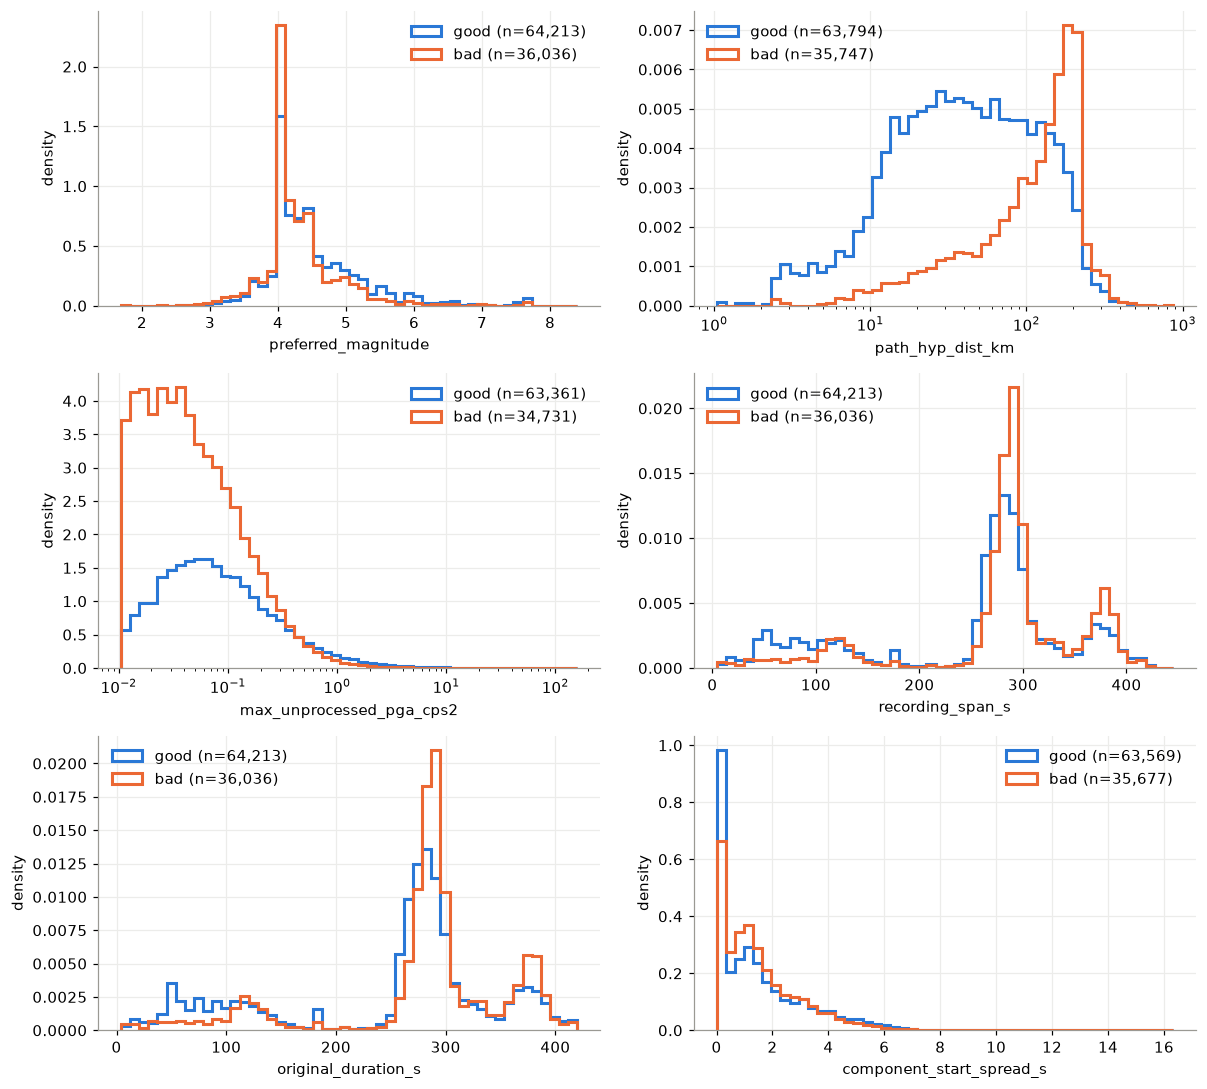

In [7]:
# (column, logarithmic axis, quantile range shown or None for the full range)
NUMERIC_PLOTS = [
    ("preferred_magnitude", False, None),
    ("path_hyp_dist_km", True, None),
    ("max_unprocessed_pga_cps2", True, (0.01, 0.99)),
    ("recording_span_s", False, None),
    ("original_duration_s", False, None),
    ("component_start_spread_s", False, (0.0, 0.99)),
]

figure, axes = plt.subplots(3, 2, figsize=(11, 10))
for ax, (column, log_scale, quantile_range) in zip(axes.ravel(), NUMERIC_PLOTS):
    plot_numeric_distribution_by_label(
        metadata, column, columns.label, label_names, ax, log_scale=log_scale, quantile_range=quantile_range
    )
figure.tight_layout()
save_figure(figure, config.output.figures_dir / "numeric_distributions_by_label.png")

Overall bad rate (dashed line): 0.359


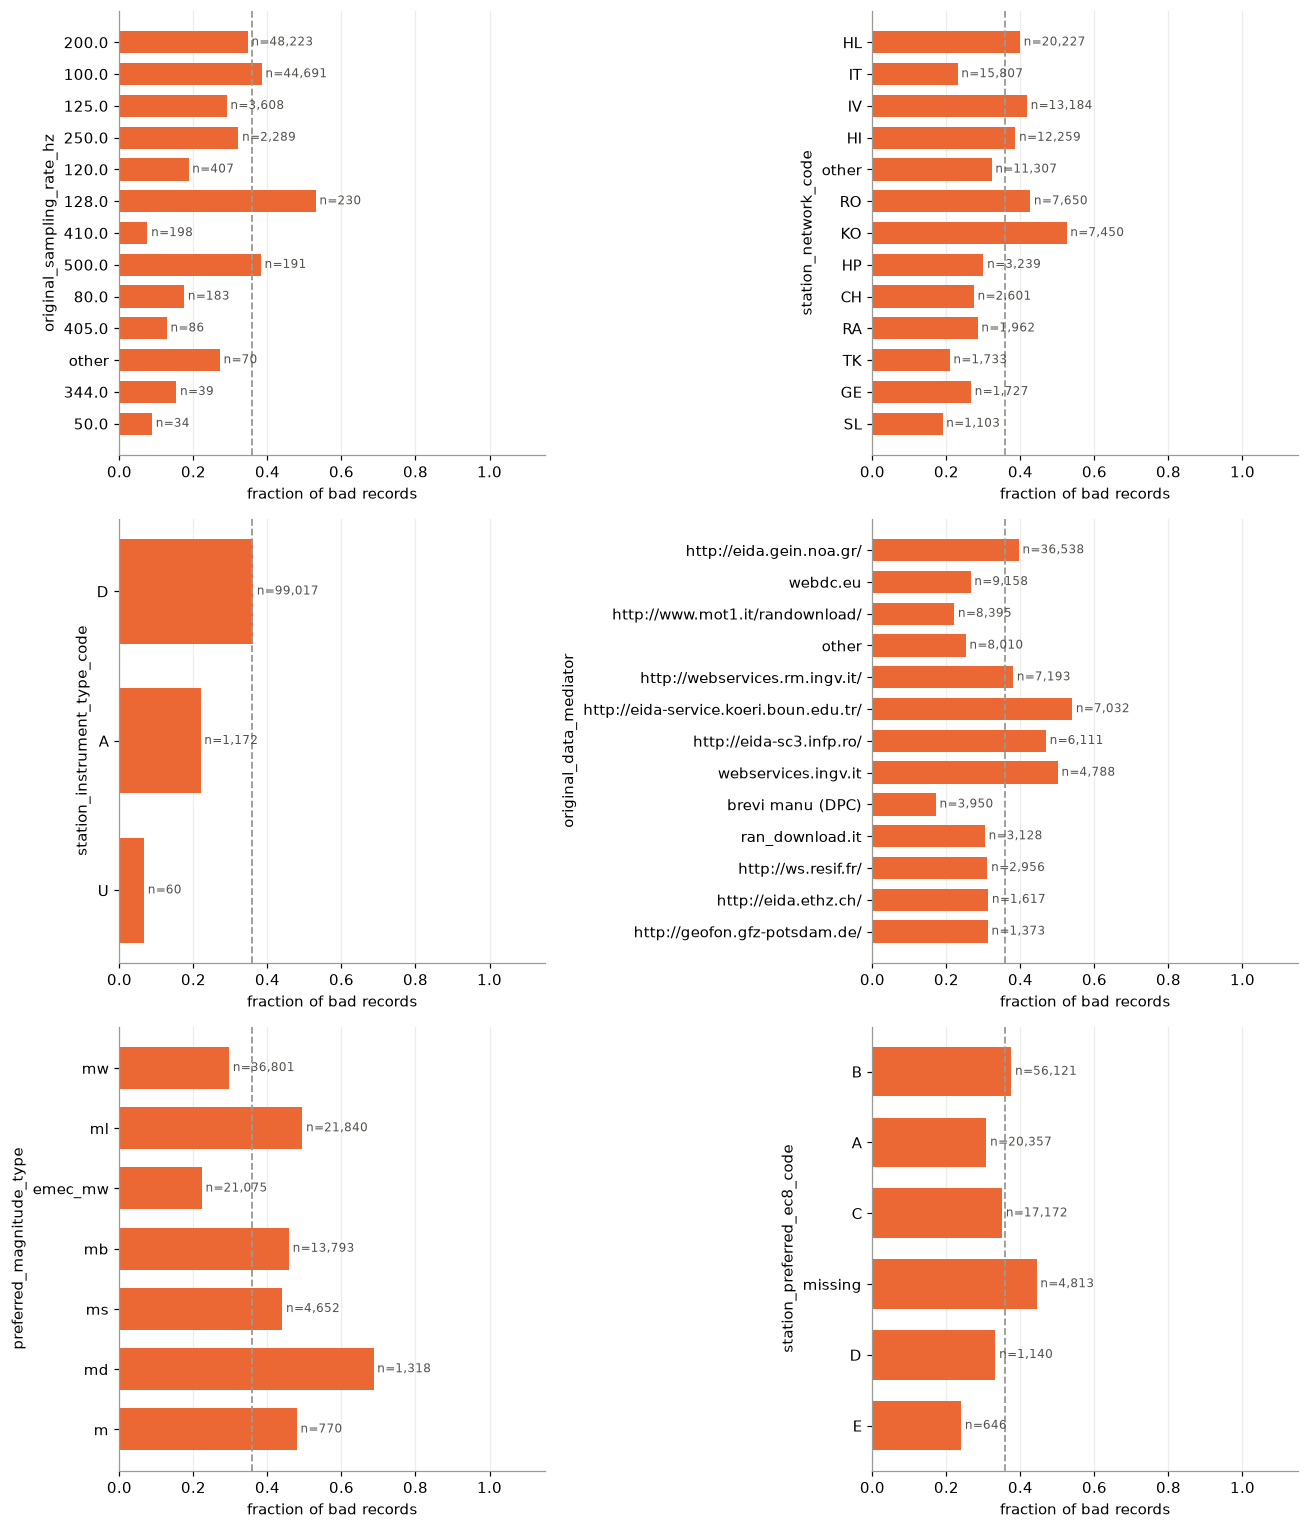

In [8]:
overall_bad_rate = float(metadata[columns.label].mean())
CATEGORY_PLOTS = [
    "original_sampling_rate_hz",
    "station_network_code",
    "station_instrument_type_code",
    "original_data_mediator",
    "preferred_magnitude_type",
    "station_preferred_ec8_code",
]

category_tables = {}
figure, axes = plt.subplots(3, 2, figsize=(12, 14))
for ax, column in zip(axes.ravel(), CATEGORY_PLOTS):
    table = categorical_distribution_by_label(metadata, column, columns.label, exploration.top_categories)
    category_tables[column] = table
    plot_category_bad_rate(table, overall_bad_rate, ax)
figure.tight_layout()
save_figure(figure, config.output.figures_dir / "bad_rate_by_category.png")
print(f"Overall bad rate (dashed line): {overall_bad_rate:.3f}")

## 4. Univariate separation of the classes

Each variable is used alone as a score for the bad class.
- Numeric variables are used directly: AUC above 0.5 means larger values indicate bad records.
- Categorical variables are scored with the bad rate of their category, estimated on other folds
  grouped by event (out-of-fold encoding), so that a record is never scored with statistics from its own event.

`separation = max(AUC, 1 - AUC)`: 0.5 means no information, 1 means perfect separation.
High separation in the physical group is expected; high separation in the acquisition group signals
a possible shortcut.

In [9]:
auc_table = univariate_auc_table(
    metadata,
    feature_groups,
    label_column=columns.label,
    group_column=columns.event_id,
    n_splits=exploration.n_splits,
    smoothing=exploration.target_encoding_smoothing,
    seed=exploration.random_seed,
)
auc_table.to_csv(config.output.tables_dir / "univariate_auc.csv", index=False)
auc_table.round(3)

,group,feature,kind,auc,separation,coverage,n_categories
0,acquisition,station_id,categorical,0.743,0.743,1.000,4173.0
1,acquisition,preferred_magnitude_type,categorical,0.627,0.627,1.000,7.0
2,acquisition,station_network_code,categorical,0.624,0.624,1.000,85.0
3,acquisition,original_data_mediator,categorical,0.616,0.616,1.000,36.0
4,acquisition,original_duration_s,numeric,0.602,0.602,1.000,NaN
5,acquisition,recording_span_s,numeric,0.601,0.601,1.000,NaN
6,acquisition,origin_year,numeric,0.580,0.580,1.000,NaN
7,acquisition,station_nation_code,categorical,0.573,0.573,0.999,53.0
8,acquisition,component_start_spread_s,numeric,0.532,0.532,1.000,NaN
9,acquisition,original_sampling_rate_hz,numeric,0.478,0.522,1.000,NaN


PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/outputs/figures/01_exploration/univariate_auc.png')

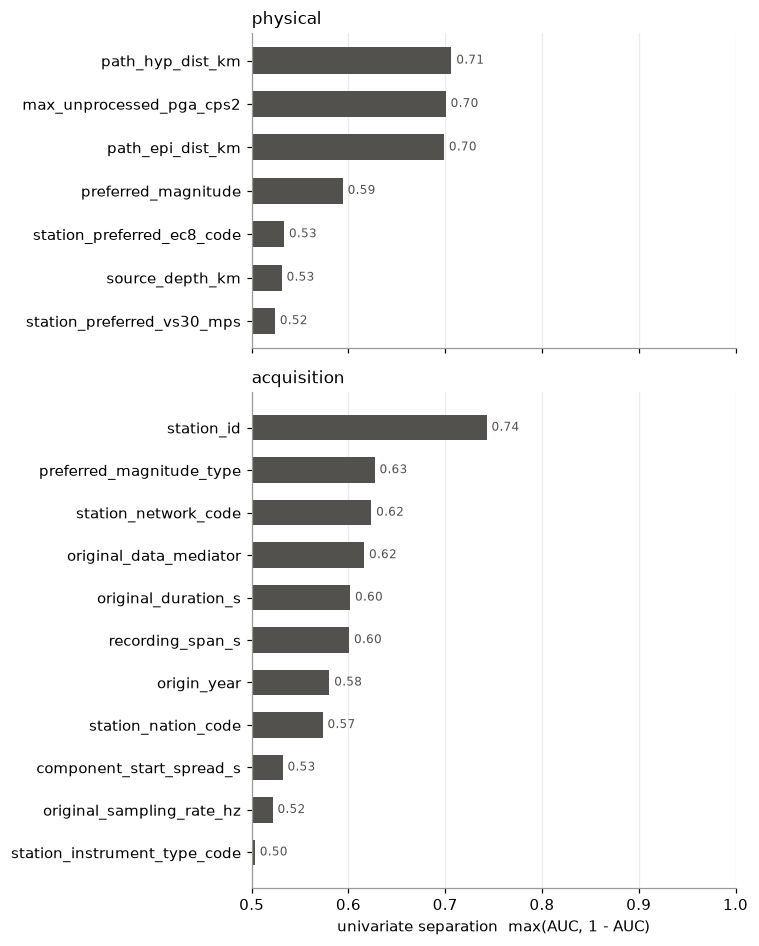

In [10]:
figure = plot_univariate_auc(auc_table, [group.name for group in feature_groups])
save_figure(figure, config.output.figures_dir / "univariate_auc.png")

## 5. Stratified bad rates

Does the association of a variable with the label persist within each level of a stratum?
If, for example, the bad rate depends on the original sampling rate only because some networks
use certain rates, the dependence disappears within each network.
Cells with fewer than `min_stratum_count` records are left empty.

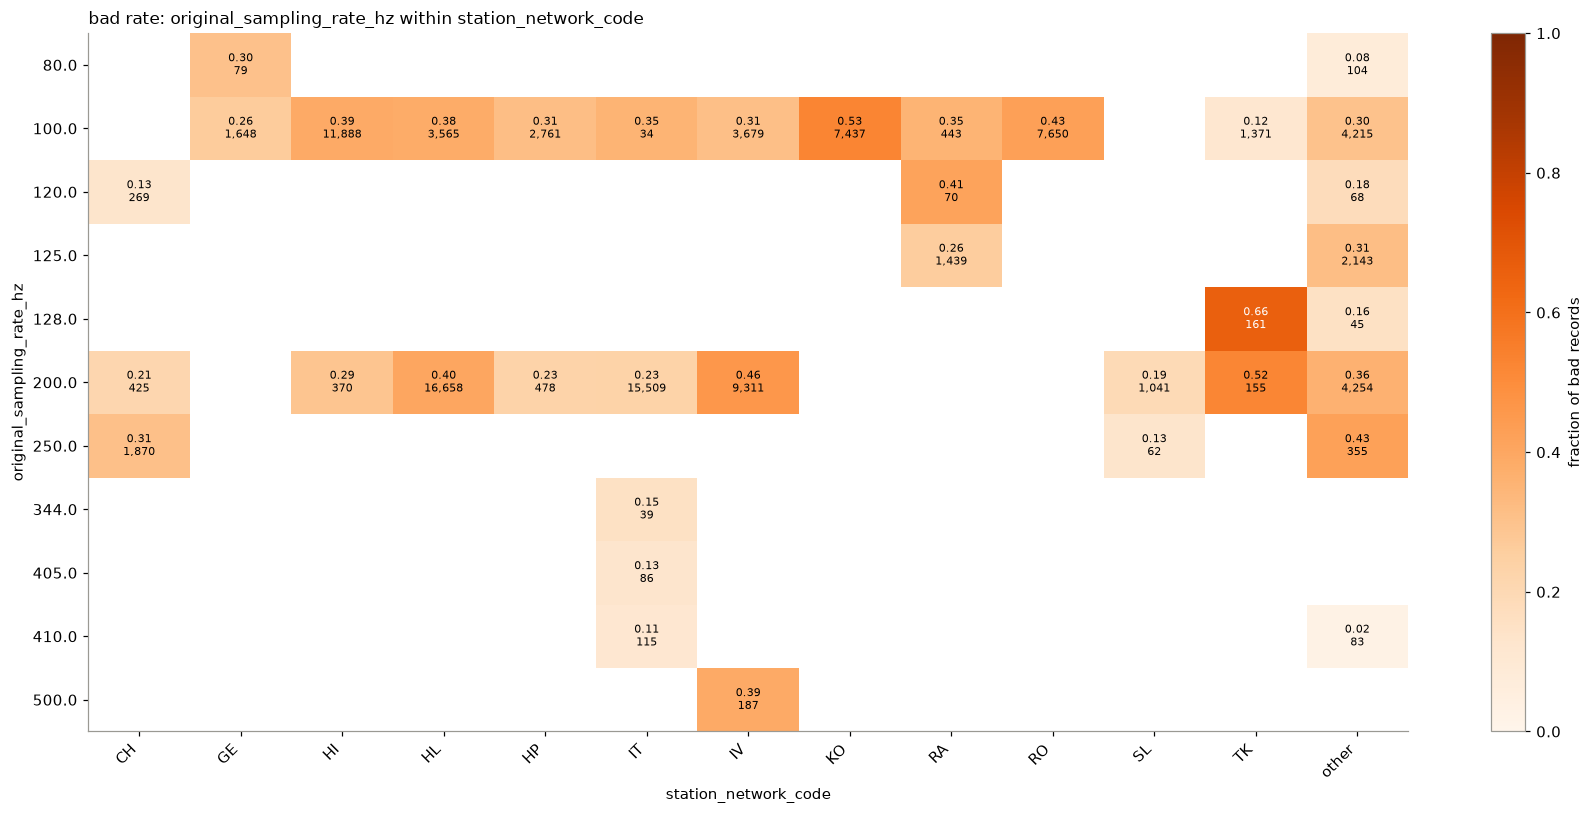

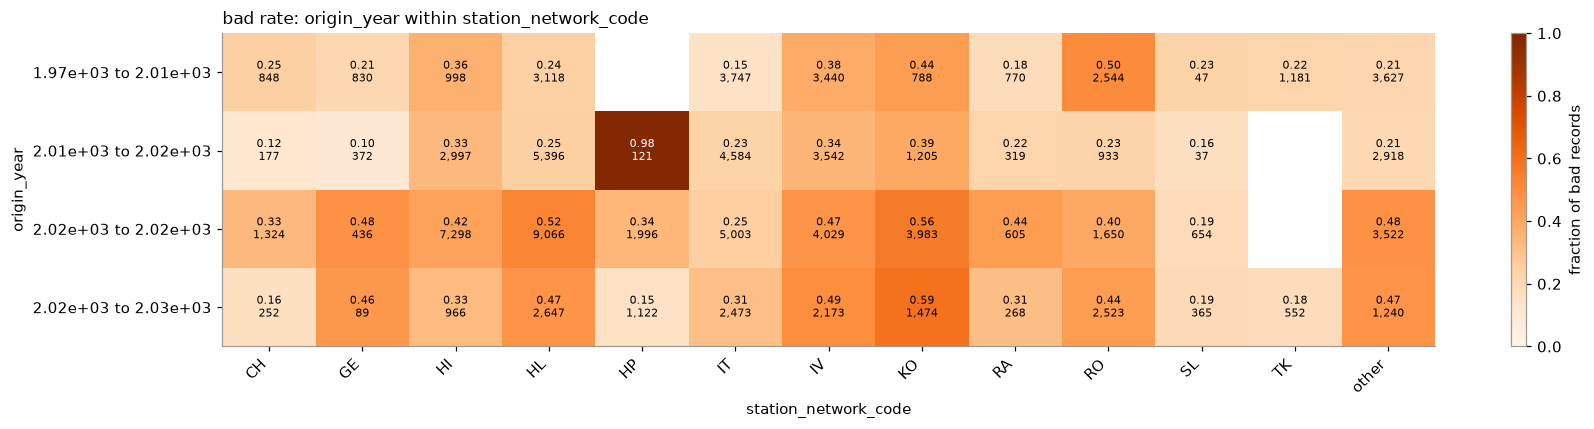

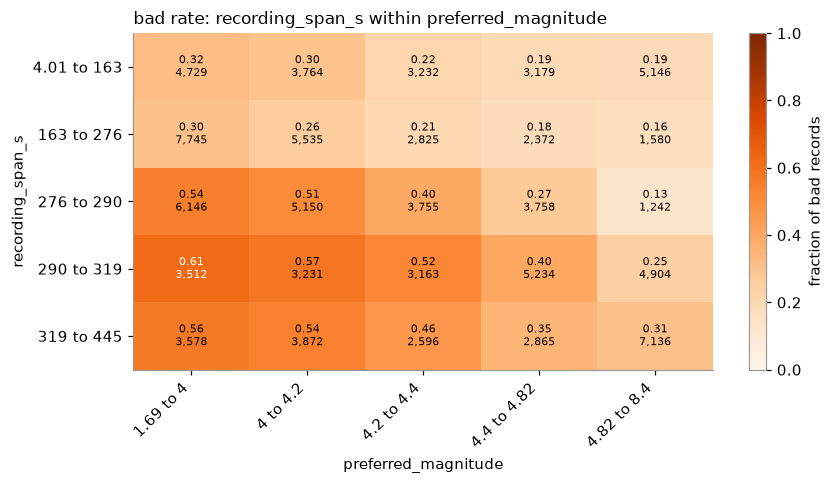

In [11]:
for comparison in exploration.stratified_comparisons:
    rates, counts = stratified_bad_rate(
        metadata,
        variable=comparison.variable,
        stratum=comparison.stratum,
        label_column=columns.label,
        n_bins=exploration.n_quantile_bins,
        top_n=exploration.top_categories,
        max_discrete_levels=exploration.max_discrete_levels,
        min_count=exploration.min_stratum_count,
    )
    figure, ax = plt.subplots(figsize=(1.0 * rates.shape[1] + 3, 0.5 * rates.shape[0] + 2))
    plot_stratified_bad_rate(rates, counts, ax)
    ax.set_title(f"bad rate: {comparison.variable} within {comparison.stratum}", loc="left")
    figure.tight_layout()
    save_figure(figure, config.output.figures_dir / f"stratified_{comparison.variable}_by_{comparison.stratum}.png")
    plt.show()

## 6. Structure for the data split

Records of the same event (and possibly of the same station) must not be split between training and test.
These tables show how many events contain both classes and how large the groups are.

In [12]:
event_overlap_summary(metadata, columns.event_id, columns.label)

,n_events,n_records
composition,,
only_good,2309,5928
only_bad,694,2478
both,3781,91843


In [13]:
group_size_summary(metadata, [columns.event_id, columns.station_id, "origin_year"]).round(1)

,n_groups,mean,std,min,25%,50%,75%,max
source_esm_id,6784.0,14.8,26.6,1.0,1.0,6.0,18.0,448.0
station_id,4173.0,24.0,62.0,1.0,2.0,6.0,18.0,751.0
origin_year,56.0,1790.2,2817.4,1.0,40.2,154.5,2480.5,10596.0


## 7. Waveform inspection

Requires `data.source: seisbench` in the configuration (waveforms downloaded into the SeisBench cache).
Shaded intervals are zero padding: front padding aligns the three components, back padding fills the trace to 420 s.

In [14]:
if config.data.source == "seisbench":
    datasets = load_seisbench_datasets(config)
    sampling_rate_hz = float(metadata["trace_sampling_rate_hz"].iloc[0])
    examples = metadata.groupby(columns.label, group_keys=False).sample(
        n=exploration.n_waveform_examples, random_state=exploration.random_seed
    )
    for _, record in examples.iterrows():
        waveform = load_record_waveform(record, datasets, columns)
        title = f"{label_names[record[columns.label]]}: {record['trace_name_old']}"
        figure = plot_waveform_with_padding(waveform, sampling_rate_hz, signal_windows_s(record), title)
        save_figure(figure, config.output.figures_dir / f"waveform_{record['trace_name_old']}.png")
        plt.show()
else:
    print("Waveform inspection skipped: set data.source to 'seisbench' once the datasets are downloaded.")

Waveform inspection skipped: set data.source to 'seisbench' once the datasets are downloaded.
